In [ ]:
#Based on Aki Taanila's Tilastoapu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

#plt.style.use('seaborn-whitegrid')

C:\Users\tlahti\AppData\Local\Temp\ipykernel_2292\2272770437.py:10: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


In [ ]:
# Open the data
df = pd.read_excel('ShopSatisfactionSurveyData.xlsx')

## Part: List the first few lines

In [ ]:
df.head()

,H,1,2,3,4,5,6,7,8,9
0,1,1,34,4,1,4,2960.0,4.0,3,2
1,2,1,67,1,1,1,980.0,1.0,5,2
2,3,2,46,3,3,5,3500.0,4.0,2,4
3,4,1,22,2,2,3,860.0,1.0,5,3
4,5,2,30,5,2,4,3380.0,4.0,2,3


In [ ]:
df.columns = ['H', 'gender', 'age', 'family_size', 'house', 'education', 'net_income', 'purchases', 'sat_product_range', 'sat_price_level']

In [ ]:
df.head()

,H,gender,age,family_size,house,education,net_income,purchases,sat_product_range,sat_price_level
0,1,1,34,4,1,4,2960.0,4.0,3,2
1,2,1,67,1,1,1,980.0,1.0,5,2
2,3,2,46,3,3,5,3500.0,4.0,2,4
3,4,1,22,2,2,3,860.0,1.0,5,3
4,5,2,30,5,2,4,3380.0,4.0,2,3


In [ ]:
df=df.drop(['H'], axis=1)

---

## Let's now analyze variables in pairs

In [ ]:
# let's check whether education and gender has some dependencies

## Part: Present the results of the cross-tabulations in tables and graphically

In [ ]:
df4 = pd.crosstab(df['education'], df['gender'], normalize = 'columns') * 100
df4.index = ['Primary school', 'Vocational school or similar', 'Secondary school graduate', 'Applied science university', 'Other university']
df4.columns = ['woman', 'man']

In [ ]:
df4

,woman,man
Primary school,14.285714,18.750
Vocational school or similar,20.000000,25.000
Secondary school graduate,10.000000,9.375
Applied science university,35.714286,25.000
Other university,20.000000,21.875


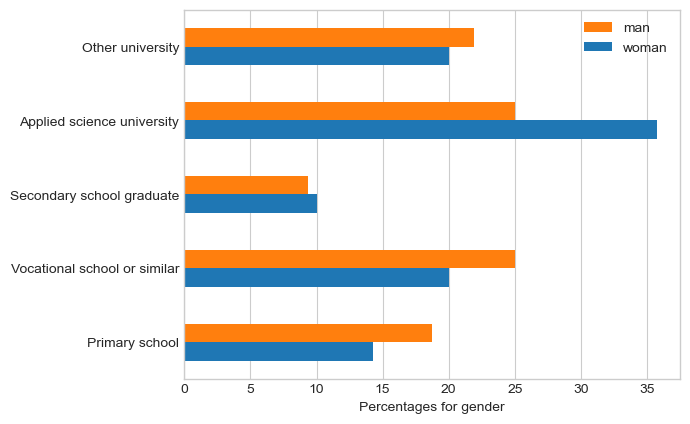

In [ ]:
df4.plot.barh(legend = 'reverse')

plt.xlabel('Percentages for gender')

plt.grid(axis = 'y')

In [ ]:
# Exercise for you, how to get the n values for both gender??

## And now the last two parts in Exercise 2

## Is the dependence observed in cross-tabulation statistically significant?

The dependencies observed in the sample may be too small to be generalized to the wider population from which the sample is taken. This may be a dependence caused by (random) sampling error.

Dependence is said to be significant if it allows a generalization to be made to the wider population from which the sample is taken. You can test the significance of the dependence by calculating the so-called p-value. The lower the p-value, the more significant the dependence. Generally, p-values less than 0.05 (5%) are considered indicative of significant dependence.

You can calculate the p-value associated with cross-tabulation with the chi-square test (chi2_contingency). The values returned by the test are chi-square, p-value, and number of degrees of freedom (df, or degrees of freedom).

# Important note!!
The following test must be done for the counts table, not for the percentages table, Hence, the df4 is not the table to use the test below!

So compare the next cell with the cell above, where we defined df4

In [ ]:
df5 = pd.crosstab(df['education'], df['gender'])
df5.index = ['Primary school', 'Vocational school or similar', 'Secondary school graduate', 'Applied science university', 'Other university']
df5.columns = ['woman', 'man']

In [ ]:
from scipy.stats import chi2_contingency


chi2_contingency(df5)

Chi2ContingencyResult(statistic=1.3590340909090908, pvalue=0.8512829058809862, dof=4, expected_freq=array([[10.98039216,  5.01960784],
       [15.09803922,  6.90196078],
       [ 6.8627451 ,  3.1372549 ],
       [22.64705882, 10.35294118],
       [14.41176471,  6.58823529]]))

## Interpretation

Since the p-value is 0.85 it is not small enough to state the there would be some dependency in education levels and genders.